# NISAR L2 GUNW (Level-2 Geocoded Unwrapped and Wrapped phase) Product Tutorial

This tutorial provides a guide to working with NISAR GUNW products, including accessing, reading, and analyzing the data.

**Author:** Heresh Fattahi, Aug 2025

## Table of Contents
1. [Introduction to GUNW](#1-introduction-to-gunw)
2. [Granule Naming Convention](#2-granule-naming-convention)
3. [Download a GUNW Product from ASF DAAC](#3-download-a-gunw-product-from-asf-daac)
4. [Explore the HDF5 Structure](#4-explore-the-hdf5-structure)
5. [Main Datasets in GUNW](#5-main-datasets-in-gunw)
6. [Correction Layers](#6-correction-layers)
7. [Unwrapping Quality Metric: Connected Components](#7-unwrapping-quality-metric-connected-components)
8. [Mask Layer](#8-mask-layer)
9. [Pixel Offsets](#9-pixel-offsets)
10. [Metadata Cube](#10-metadata-cube)
11. [Phase Sign Convention](#11-phase-sign-convention)
12. [Processing Information](#12-processing-information)
13. [QA Report and Browse](#13-qa-report-and-browse)

## Setup and Import Required Libraries

In [1]:
import os
import h5py
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from osgeo import gdal, osr
import warnings
warnings.filterwarnings('ignore')

# Set display options
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.size'] = 10

## 1. Introduction to GUNW

### What is GUNW?

The **GUNW (Geocoded Unwrapped Interferogram)** product is a Level-2 (L2) product. It provides geocoded, multi-looked, ellipsoid and topography-flattened unwrapped interferometric phase and coherence at 80 m posting with several correction layers and with an additional geocoded wrapped phase at 20 m posting.

### Key Features:

- **Product Level**: Level 2 (geocoded and map-projected)
- **Format**: HDF5 (Hierarchical Data Format version 5)
- **Coordinate System**: UTM or Polar Stereographic projection
- **Spatial Coverage**: Pre-defined track/frame (typically 240 km × 240 km)
- **Temporal Baseline**: Nearest pair in time
- **Polarization**: Co-pol channels only (HH or VV)

### What's Inside GUNW?

1. **Geocoded Unwrapped interferometric phase** (80 m posting)
2. **Geocoded Wrapped complex interferogram** (20 m posting)
3. **Coherence magnitude** (20 m and 80 m posting)
4. **Connected components mask** (unwrapping quality)
5. **Mask**: water mask, valid data mask of input reference and secondary RSLCs, data exception mask, ionosphere mask
7. **Pixel offsets** (along-track and slant range, 80 m posting)
8. **Correction layers** (ionosphere, troposphere, solid Earth tides)
9. **Metadata cubes** (incidence angle, baseline, etc.)

### Product Dependency

GUNW is derived from:
- **RIFG** (Range-Doppler Interferogram)
- **RUNW** (Range-Doppler Unwrapped Interferogram)

Which in turn are derived from:
- **RSLC** (Range-Doppler Single Look Complex) products

## 2. Granule Naming Convention

NISAR GUNW products follow the NISAR Standard Product File Naming Scheme (JPL D-102255).

### Naming Format:

```
NISAR_IL_PT_PROD_CYL_REL_P_FRM_SCY_MODE_PO_RefStartDateTime_RefEndDateTime_SecStartDateTime_SecEndDateTime_CRID_A_C_LOC_CTR.EXT

NISAR_L2_PR_GUNW_022_162_A_007_023_4000_SH_20260613T100656_20260613T100731_20260625T100655_20260625T100730_P05023_N_F_J_001.h5
```

Where:

* **`NISAR`** – 5 characters for mission: `nisar`
* **`I`** – 1 character for instrument:
    * `L` for L-SAR
    * `S` for S-SAR
* **`L`** – 1 character for processing level: `1` or `2`
* **`PT`** – 2 characters for processing type:
    * `PR` – Production
    * `UR` – Urgent response
    * `OD` – Science on-demand
* **`PROD`** – 4 characters for product ID: `rifg`, `runw`, `gunw`, `roff`, `goff`
* **`CYL`** – 3 characters for cycle number in the mission. Each cycle represents 12 days, zero-padded, starting at `001` [rd1].
* **`REL`** – 3 characters for relative orbit track number within a cycle. Resets to `1` with a cycle number increment, zero-padded. Valid values: `001`-`173` [rd1].
* **`P`** – 1 character for direction of movement of the satellite at the time of imaging [rd1]:
    * `A` for ascending
    * `D` for descending
* **`FRM`** – 3 characters for track frame number, a segment of an orbital track corresponding to the product, zero-padded. Valid values: `001`-`176` on each track (see sec 4.5).
* **`SCY`** – 3 characters for the second cycle number.
* **`MODE`** – 4 characters for bandwidth mode code of primary and secondary:
    * `40`, `20`, `77`, `05`, or `00` (only if the secondary band is missing)
* **`PO`** – 2 characters for polarization:
    * *Note: The polarization pair notation refers to the transmit and receive polarizations, respectively, of the main band and the side band of the reference (e.g., hv refers to h transmit and v receive).*
    * `SV` = VV – single polarity
    * `SH` = HH – single polarity
    * `DH` = HH/HV – dual polarity
    * `DV` = VV/VH – dual polarity
    * `CL` = LH/LV – compact polarity
    * `CR` = RH/RV – compact polarity
    * `QP` = HH/HV/VV/VH – quad polarity
    * `QH` = HH/HV + VV/VH – quasi quad polarity
    * `QV` = VV/VH + HH/HV – quasi quad polarity
    * `QD` = HH/VV – quasi dual pole
* **`RefStartDateTime`** – 15 characters for the data from the reference listed cycle contained in the file as `yyyymmddThhmmss`, UTC.
* **`RefEndDateTime`** – 15 characters for the data from the reference listed cycle contained in the file as `yyyymmddThhmmss`, UTC.
* **`SecStartDateTime`** – 15 characters for the data from the secondary listed cycle contained in the file as `yyyymmddThhmmss`, UTC.
* **`SecEndDateTime`** – 15 characters for the data from the secondary listed cycle contained in the file as `yyyymmddThhmmss`, UTC.


## 3. Download a GUNW Product from ASF DAAC

NISAR data products are distributed through the **Alaska Satellite Facility (ASF) Distributed Active Archive Center (DAAC)**.

### Methods to Access Data:

1. **ASF Data Search (Vertex)**: https://search.asf.alaska.edu/
2. **ASF Data Search API**: Programmatic access
3. **Earthdata Search**: https://search.earthdata.nasa.gov/

With one of the different available tools download this GUNW product over Los Angeles. Alternatively run the following cell to download the product or copy paste the following command to terminal:

wget https://nisar.asf.earthdatacloud.nasa.gov/NISAR/NISAR_L2_GUNW_PROVISIONAL_V1/NISAR_L2_PR_GUNW_024_013_D_071_025_4000_SH_20260627T024036_20260627T024114_20260709T024036_20260709T024113_P05023_N_F_J_001/NISAR_L2_PR_GUNW_024_013_D_071_025_4000_SH_20260627T024036_20260627T024114_20260709T024036_20260709T024113_P05023_N_F_J_001.h5



In [2]:
#!wget https://nisar.asf.earthdatacloud.nasa.gov/NISAR/NISAR_L2_GUNW_PROVISIONAL_V1/NISAR_L2_PR_GUNW_024_013_D_071_025_4000_SH_20260627T024036_20260627T024114_20260709T024036_20260709T024113_P05023_N_F_J_001/NISAR_L2_PR_GUNW_024_013_D_071_025_4000_SH_20260627T024036_20260627T024114_20260709T024036_20260709T024113_P05023_N_F_J_001.h5

In [3]:
!ls nisar_test/

environment.yml
LICENSE
NISAR_L2_PR_GUNW_022_162_A_007_023_4000_SH_20260613T100656_20260613T100731_20260625T100655_20260625T100730_P05023_N_F_J_001.h5
README.md


In [4]:

# For this tutorial, we'll use a sample file path
gunw_file = 'nisar_test/NISAR_L2_PR_GUNW_022_162_A_007_023_4000_SH_20260613T100656_20260613T100731_20260625T100655_20260625T100730_P05023_N_F_J_001.h5'

print(f"GUNW file: {gunw_file}")

GUNW file: nisar_test/NISAR_L2_PR_GUNW_022_162_A_007_023_4000_SH_20260613T100656_20260613T100731_20260625T100655_20260625T100730_P05023_N_F_J_001.h5


In [5]:
# Specify the path to your GUNW file
# Update this path to point to your downloaded GUNW file
# Check if file exists
if not os.path.exists(gunw_file):
    print(f"File not found: {gunw_file}")
    print("Please update the path to your GUNW file. If you don't have a GUNW file, please download one. See the cell above")
else:
    print(f"File found: {gunw_file}")
    file_size = os.path.getsize(gunw_file) / (1024**3)  # Size in GB
    print(f"File size: {file_size:.2f} GB")

File found: nisar_test/NISAR_L2_PR_GUNW_022_162_A_007_023_4000_SH_20260613T100656_20260613T100731_20260625T100655_20260625T100730_P05023_N_F_J_001.h5
File size: 2.18 GB


## 4. Explore the HDF5 Structure

NISAR products are stored in HDF5 format, which provides:
- Hierarchical organization (similar to a file system)
- Efficient storage and access
- Self-describing metadata
- Cross-platform compatibility

### HDF5 Key Concepts:

- **File**: Container for all data
- **Groups**: Like directories, organize data hierarchically
- **Datasets**: Arrays of data
- **Attributes**: Metadata attached to Groups or Datasets
- **Datatypes**: Define the format of data elements

In [6]:
def explore_hdf5_structure(filename, max_depth=5):
    """
    Recursively explore and print HDF5 file structure
    """
    def print_structure(name, obj, depth=0):
        if depth > max_depth:
            return
        
        indent = '  ' * depth
        if isinstance(obj, h5py.Group):
            print(f"{indent}📁 {name}/")
        elif isinstance(obj, h5py.Dataset):
            print(f"{indent}📄 {name} {obj.shape} {obj.dtype}")
    
    with h5py.File(filename, 'r') as f:
        print(f"\nHDF5 File: {filename}\n")
        print("=" * 80)
        f.visititems(print_structure)

explore_hdf5_structure(gunw_file, max_depth=4)


HDF5 File: nisar_test/NISAR_L2_PR_GUNW_022_162_A_007_023_4000_SH_20260613T100656_20260613T100731_20260625T100655_20260625T100730_P05023_N_F_J_001.h5

📁 science/
📁 science/LSAR/
📁 science/LSAR/GUNW/
📁 science/LSAR/GUNW/grids/
📁 science/LSAR/GUNW/grids/frequencyA/
📄 science/LSAR/GUNW/grids/frequencyA/centerFrequency () float64
📄 science/LSAR/GUNW/grids/frequencyA/listOfPolarizations (1,) |S2
📁 science/LSAR/GUNW/grids/frequencyA/pixelOffsets/
📁 science/LSAR/GUNW/grids/frequencyA/pixelOffsets/HH/
📄 science/LSAR/GUNW/grids/frequencyA/pixelOffsets/HH/alongTrackOffset (4149, 4239) float32
📄 science/LSAR/GUNW/grids/frequencyA/pixelOffsets/HH/correlationSurfacePeak (4149, 4239) float32
📄 science/LSAR/GUNW/grids/frequencyA/pixelOffsets/HH/projection () uint32
📄 science/LSAR/GUNW/grids/frequencyA/pixelOffsets/HH/slantRangeOffset (4149, 4239) float32
📄 science/LSAR/GUNW/grids/frequencyA/pixelOffsets/HH/xCoordinateSpacing () float64
📄 science/LSAR/GUNW/grids/frequencyA/pixelOffsets/HH/xCoordinates

### GUNW HDF5 Group Organization

```
/
└── science/
    └── LSAR/
        ├── identification/          # Product identification metadata
        └── GUNW/
            ├── grids/
            │   └── frequencyA/      # Main imaging band (77 MHz)
            │       ├── wrappedInterferogram/
            │       │   ├── HH/      # or VV
            │       │   │   ├── wrappedInterferogram
            │       │   │   ├── coherenceMagnitude
            │       │   │   ├── xCoordinates
            │       │   │   ├── yCoordinates
            │       │   │   └── projection
            │       ├── unwrappedInterferogram/
            │       │   ├── HH/      # or VV
            │       │   │   ├── unwrappedPhase
            │       │   │   ├── coherenceMagnitude
            │       │   │   ├── connectedComponents
            │       │   │   ├── ionospherePhaseScreen
            │       │   │   ├── ionospherePhaseScreenUncertainty
            │       │   │   ├── mask
            │       │   │   └── ...
            │       └── pixelOffsets/
            │           └── HH/      # or VV
            │               ├── alongTrackOffset
            │               ├── slantRangeOffset
            │               └── correlationSurfacePeak
            └── metadata/
                ├── processingInformation/
                │   ├── parameters/
                │   ├── algorithms/
                │   └── inputs/
                ├── orbit/
                ├── attitude/
                └── radarGrid/       # Metadata cubes
```

In [8]:
# Function to read identification metadata
def print_identification_info(filename):
    """
    Print product identification information
    """
    with h5py.File(filename, 'r') as f:
        id_group = f['/science/LSAR/identification']
        fields = f['/science/LSAR/identification'].keys()
        print("\nProduct Identification:")
        print("=" * 80)
        
        # Print important identification fields
        #fields = [
        #    'productVersion',
        #    'processingDateTime',
        #    'missionId',
        #    'trackNumber',
        #    'frameNumber',
        #    'orbitPassDirection',
        #    'lookDirection'
        #]
        
        for field in fields:
            if field in id_group:
                value = id_group[field][()]
                if isinstance(value, bytes):
                    value = value.decode('utf-8')
                print(f"{field:30s}: {value}")

# Example usage:
print_identification_info(gunw_file)


Product Identification:
boundingPolygon               : POLYGON ((-66.8492652572176 10.0666310671822 655.211791332998,-66.8984790855908 10.2814721890029 559.35021953819,-66.9567123368598 10.4942464684216 1130.06762695253,-66.9919844264641 10.7123299819919 -20.1833572628954,-67.0427477766314 10.9268546590231 -22.1697158954752,-67.0936113627312 11.1413689901802 -24.2502651406892,-67.144588257944 11.3558710012074 -25.5614471647056,-67.1956810194313 11.570359304095 -25.9923572752731,-67.2468762799817 11.7848372466147 -26.6313686782321,-67.2981652882577 11.9993075616803 -28.2288628452037,-67.3495342705371 12.2137725434902 -31.8795796753872,-67.6097792214075 12.1532466912971 -28.3704795998235,-67.858944026695 12.0950421737705 -27.6335029605995,-68.098860563266 12.0387626094469 -25.0116977929593,-68.3308607420291 11.9841211691155 -23.3035755148685,-68.5560144191971 11.9308871643643 -23.2756175992301,-68.7752080715513 11.8788689228471 -22.9443058167585,-68.9891401195248 11.8279159807822 -23.1

## 5. Main Datasets in GUNW

The GUNW product contains several key datasets organized by resolution:

### 5.1 Unwrapped Phase (80 m posting)

**Path:** `/science/LSAR/GUNW/grids/frequencyA/unwrappedInterferogram/[HH/VV]/unwrappedPhase`

- **Units:** Radians
- **Data Type:** float32
- **Grid Spacing:** 80 m
- **Description:** Geocoded, multi-looked, ellipsoid and topography-flattened unwrapped interferometric phase
- **Sign Convention:** 
  - **Positive phase** → Range increase (moving away from sensor)
  - **Negative phase** → Range decrease (moving toward sensor)

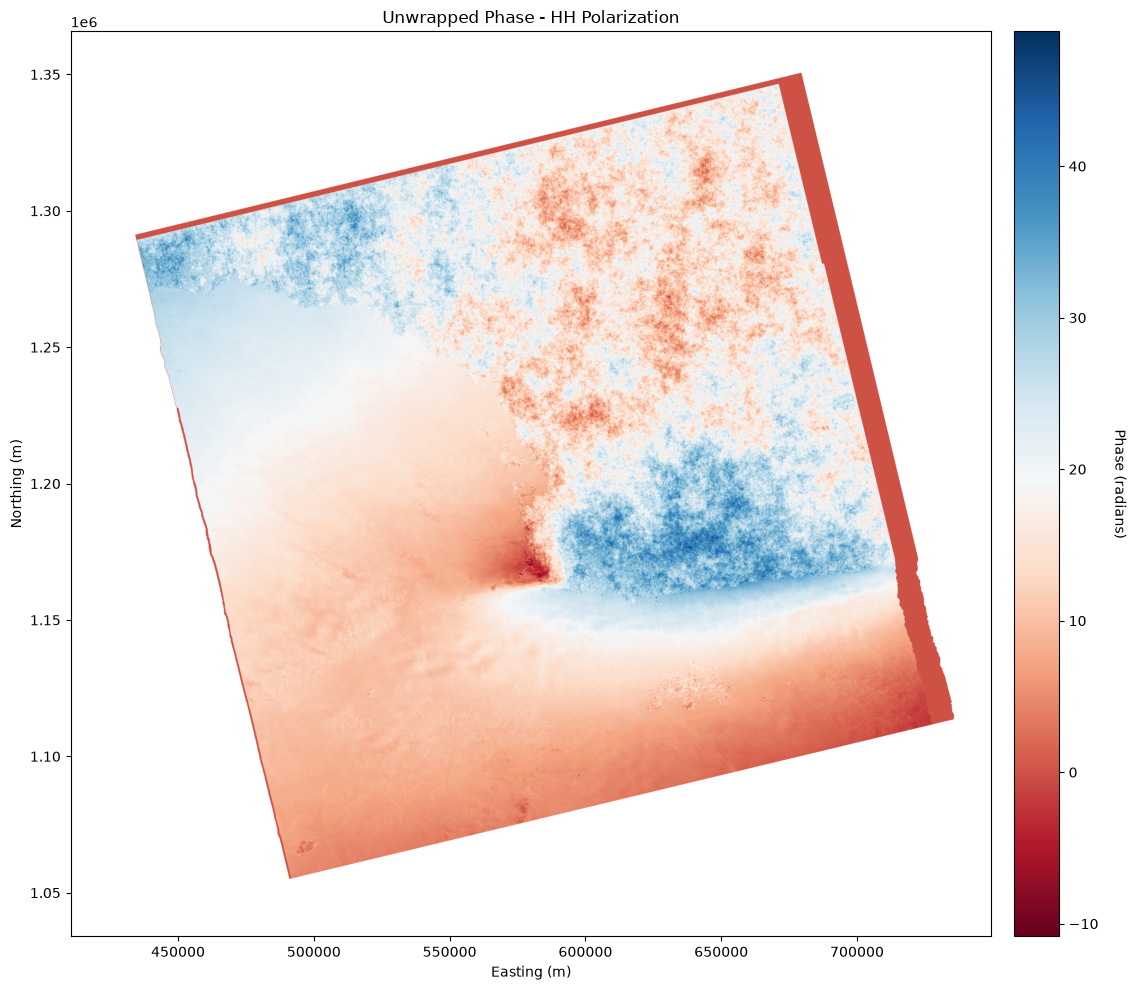


Unwrapped Phase Statistics (HH):
  Shape: (4149, 4239)
  Min: -10.845 rad
  Max: 48.900 rad
  Mean: 15.368 rad
  Std: 8.275 rad
  Valid pixels: 9601173 / 17587611 (54.6%)


In [9]:
def read_unwrapped_phase(filename, polarization='HH'):
    """
    Read and display unwrapped phase
    """
    with h5py.File(filename, 'r') as f:
        # Read unwrapped phase
        phase_path = f'/science/LSAR/GUNW/grids/frequencyA/unwrappedInterferogram/{polarization}/unwrappedPhase'
        phase = f[phase_path][:]
        
        # Read coordinates
        x_coords = f[f'/science/LSAR/GUNW/grids/frequencyA/unwrappedInterferogram/{polarization}/xCoordinates'][:]
        y_coords = f[f'/science/LSAR/GUNW/grids/frequencyA/unwrappedInterferogram/{polarization}/yCoordinates'][:]
        
        # Read attributes
        attrs = dict(f[phase_path].attrs)
        
    # Plot
    fig, ax = plt.subplots(1, 1, figsize=(12, 10))
    
    im = ax.imshow(phase, cmap='RdBu', aspect='auto',
                   extent=[x_coords[0], x_coords[-1], y_coords[-1], y_coords[0]])
    ax.set_xlabel('Easting (m)')
    ax.set_ylabel('Northing (m)')
    ax.set_title(f'Unwrapped Phase - {polarization} Polarization')
    
    cbar = plt.colorbar(im, ax=ax, orientation='vertical', pad=0.02)
    cbar.set_label('Phase (radians)', rotation=270, labelpad=20)
    
    plt.tight_layout()
    plt.show()
    
    # Print statistics
    valid_phase = phase[~np.isnan(phase)]
    print(f"\nUnwrapped Phase Statistics ({polarization}):")
    print(f"  Shape: {phase.shape}")
    print(f"  Min: {np.nanmin(phase):.3f} rad")
    print(f"  Max: {np.nanmax(phase):.3f} rad")
    print(f"  Mean: {np.nanmean(phase):.3f} rad")
    print(f"  Std: {np.nanstd(phase):.3f} rad")
    print(f"  Valid pixels: {len(valid_phase)} / {phase.size} ({100*len(valid_phase)/phase.size:.1f}%)")
    
    return phase, x_coords, y_coords

# Example usage:
phase, x, y = read_unwrapped_phase(gunw_file, polarization='HH')

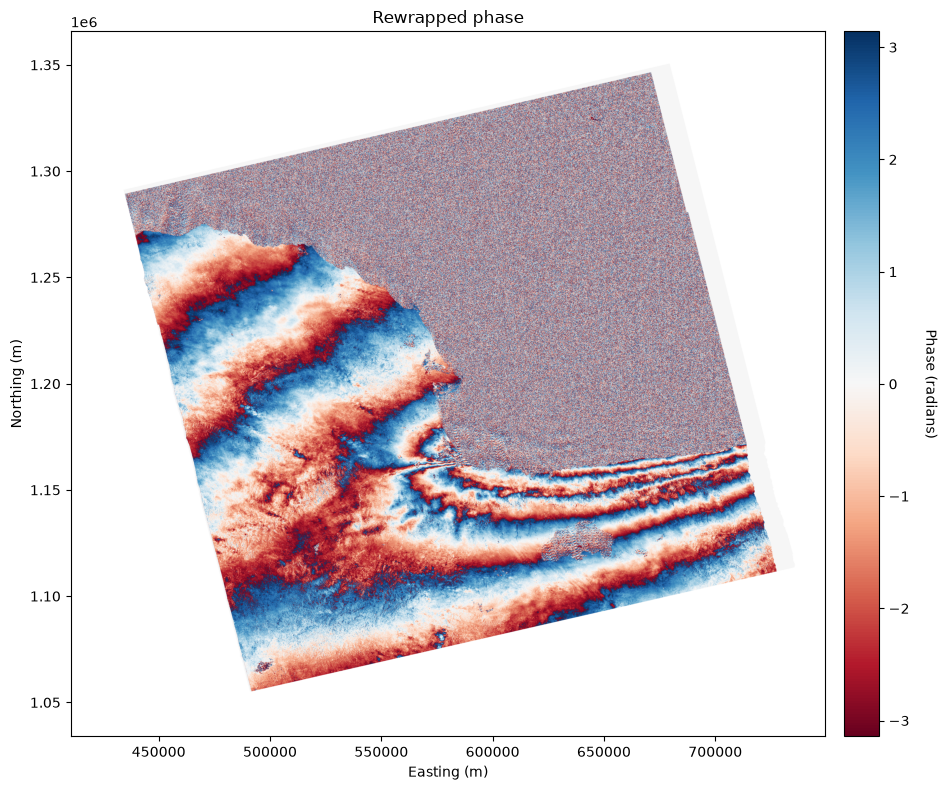

In [10]:
fig, ax = plt.subplots(1, 1, figsize=(10, 8))
    
im = ax.imshow(np.angle(np.exp(1J*phase)), cmap='RdBu', aspect='auto',
                   extent=[x[0], x[-1], y[-1], y[0]])
ax.set_xlabel('Easting (m)')
ax.set_ylabel('Northing (m)')
ax.set_title(f'Rewrapped phase')
    
cbar = plt.colorbar(im, ax=ax, orientation='vertical', pad=0.02)
cbar.set_label('Phase (radians)', rotation=270, labelpad=20)
    
plt.tight_layout()
plt.show()

### 5.2 Coherence Magnitude (80 m posting)

**Path:** `/science/LSAR/GUNW/grids/frequencyA/unwrappedInterferogram/[HH/VV]/coherenceMagnitude`

- **Units:** Dimensionless (0-1)
- **Data Type:** float32
- **Grid Spacing:** 80 m
- **Description:** Normalized interferometric coherence magnitude
- **Interpretation:**
  - **1.0**: Perfect coherence
  - **0.0**: Complete decorrelation

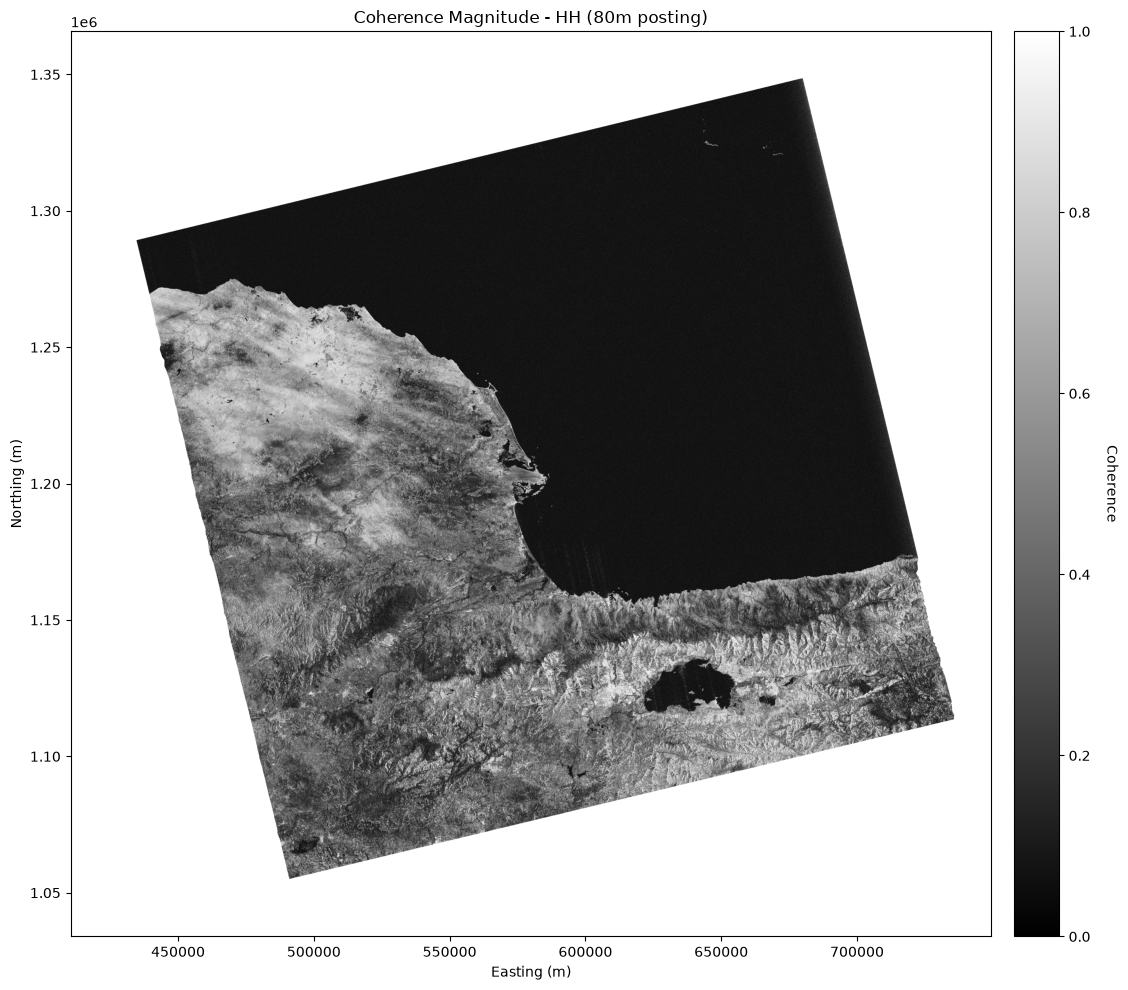


Coherence Statistics (HH, 80m):
  Shape: (4149, 4239)
  Min: 0.001
  Max: 0.998
  Mean: 0.282
  Median: 0.170


In [11]:
def read_coherence(filename, polarization='HH', posting='80m'):
    """
    Read and display coherence magnitude
    """
    with h5py.File(filename, 'r') as f:
        # Choose path based on posting
        if posting == '80m':
            base_path = f'/science/LSAR/GUNW/grids/frequencyA/unwrappedInterferogram/{polarization}'
        else:  # 20m
            base_path = f'/science/LSAR/GUNW/grids/frequencyA/wrappedInterferogram/{polarization}'
        
        coherence = f[f'{base_path}/coherenceMagnitude'][:]
        x_coords = f[f'{base_path}/xCoordinates'][:]
        y_coords = f[f'{base_path}/yCoordinates'][:]
    
    # Plot
    fig, ax = plt.subplots(1, 1, figsize=(12, 10))
    
    im = ax.imshow(coherence, cmap='gray', vmin=0, vmax=1, aspect='auto',
                   extent=[x_coords[0], x_coords[-1], y_coords[-1], y_coords[0]])
    ax.set_xlabel('Easting (m)')
    ax.set_ylabel('Northing (m)')
    ax.set_title(f'Coherence Magnitude - {polarization} ({posting} posting)')
    
    cbar = plt.colorbar(im, ax=ax, orientation='vertical', pad=0.02)
    cbar.set_label('Coherence', rotation=270, labelpad=20)
    
    plt.tight_layout()
    plt.show()
    
    # Print statistics
    valid_coh = coherence[~np.isnan(coherence)]
    print(f"\nCoherence Statistics ({polarization}, {posting}):")
    print(f"  Shape: {coherence.shape}")
    print(f"  Min: {np.nanmin(coherence):.3f}")
    print(f"  Max: {np.nanmax(coherence):.3f}")
    print(f"  Mean: {np.nanmean(coherence):.3f}")
    print(f"  Median: {np.nanmedian(coherence):.3f}")
    
    return coherence

# Example usage:
coherence = read_coherence(gunw_file, polarization='HH', posting='80m')

### 5.3 Wrapped Interferogram (20 m posting)

**Path:** `/science/LSAR/GUNW/grids/frequencyA/wrappedInterferogram/[HH/VV]/wrappedInterferogram`

- **Data Type:** Complex64 (float32 real + float32 imaginary)
- **Grid Spacing:** 20 m
- **Description:** Complex wrapped interferogram (multi-looked at 30 m in range-Doppler, geocoded at 20 m)
- **Phase Range:** -π to +π radians

nisar_test/NISAR_L2_PR_GUNW_022_162_A_007_023_4000_SH_20260613T100656_20260613T100731_20260625T100655_20260625T100730_P05023_N_F_J_001.h5
(16596, 16956)
shape of extracted data with stride of 10:  (1660, 1696)


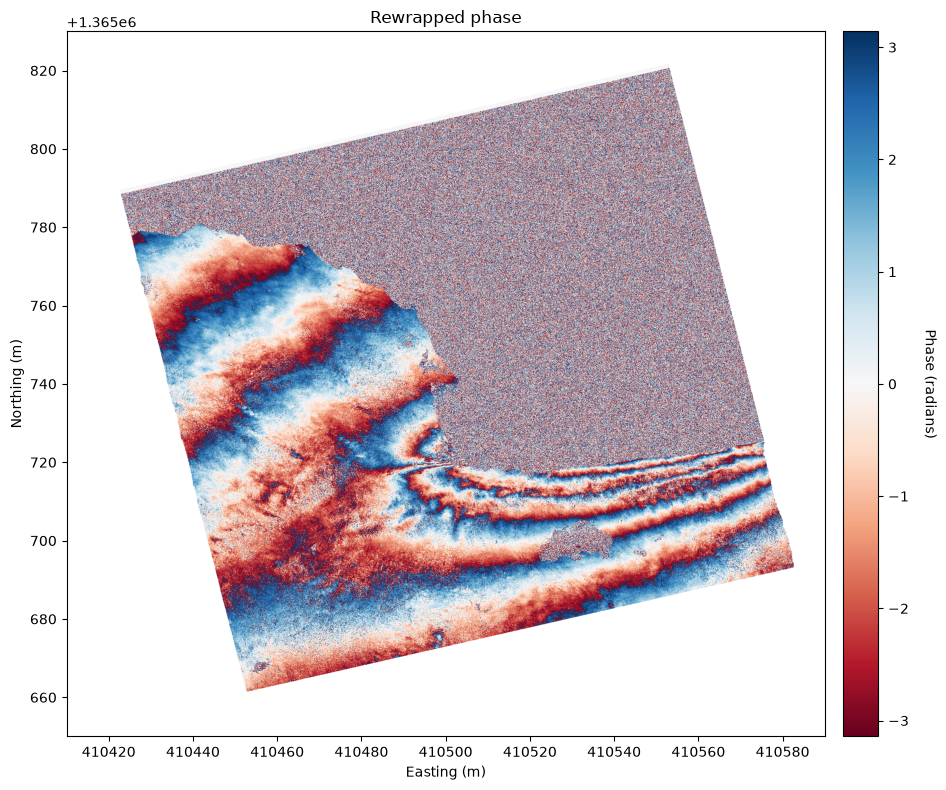

In [12]:
def read_wrapped_interferogram(filename, polarization='HH', stride = 1):
    """
    Read and display wrapped interferogram
    """
    print(filename)
    with h5py.File(filename, 'r') as f:
        base_path = f'/science/LSAR/GUNW/grids/frequencyA/wrappedInterferogram/{polarization}'
        print(f[f'{base_path}/wrappedInterferogram'].shape)
        # Read complex interferogram
        ifg = f[f'{base_path}/wrappedInterferogram'][::stride, ::stride]
        
        # Calculate phase and amplitude
        phase = np.angle(ifg)
        #amplitude = np.abs(ifg)
        print(f"shape of extracted data with stride of {stride}: ", phase.shape)
        x_coords = f[f'{base_path}/xCoordinates'][:stride]
        y_coords = f[f'{base_path}/yCoordinates'][:stride]
    
    return phase, x_coords, y_coords

wrapped_phase, x, y = read_wrapped_interferogram(gunw_file, polarization='HH', stride = 10)

fig, ax = plt.subplots(1, 1, figsize=(10, 8))
    
im = ax.imshow(wrapped_phase, cmap='RdBu', aspect='auto',
                   extent=[x[0], x[-1], y[-1], y[0]])
ax.set_xlabel('Easting (m)')
ax.set_ylabel('Northing (m)')
ax.set_title(f'Rewrapped phase')
    
cbar = plt.colorbar(im, ax=ax, orientation='vertical', pad=0.02)
cbar.set_label('Phase (radians)', rotation=270, labelpad=20)
    
plt.tight_layout()
plt.show()

In [13]:
print(wrapped_phase.shape)
print(phase.shape)

(1660, 1696)
(4149, 4239)


### 5.4 Coherence Magnitude at 20 m posting

**Path:** `/science/LSAR/GUNW/grids/frequencyA/wrappedInterferogram/[HH/VV]/coherenceMagnitude`

- **Units:** Dimensionless (0-1)
- **Data Type:** float32
- **Grid Spacing:** 20 m
- **Description:** Higher resolution coherence magnitude corresponding to wrapped interferogram

## 6. Correction Layers

GUNW products include several atmospheric and geophysical correction layers. These corrections are **provided as separate layers but NOT applied to the data by default**. Users must apply them based on their analysis needs.

### 6.1 Ionospheric Phase Screen

**Path:** `/science/LSAR/GUNW/grids/frequencyA/unwrappedInterferogram/[HH/VV]/ionospherePhaseScreen`

- **Units:** Radians
- **Data Type:** float32
- **Grid Spacing:** 80 m
- **Method:** 
  - Split-spectrum technique using frequencyA and frequencyB when available
  - Range split-spectrum on frequencyA alone during mode transitions
- **Uncertainty:** Provided in `ionospherePhaseScreenUncertainty`

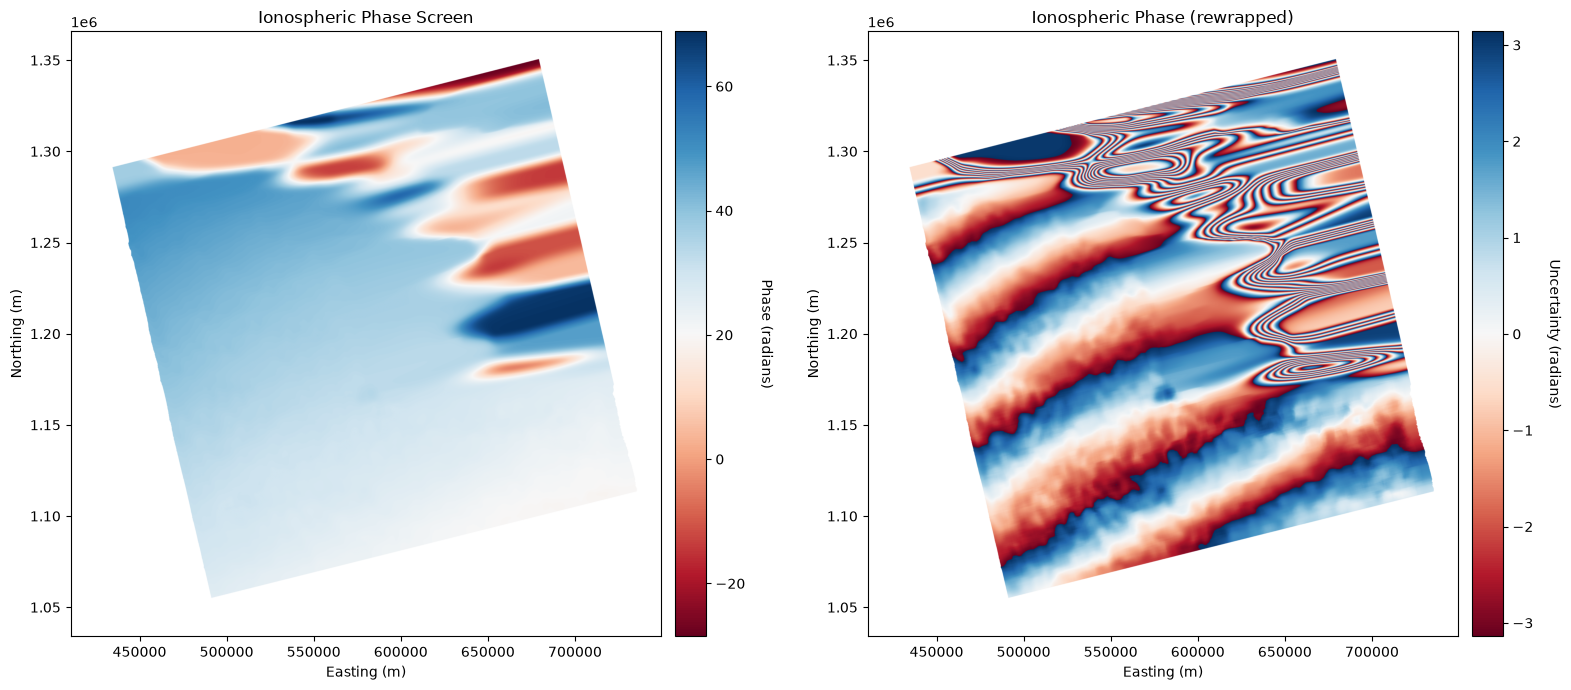


Ionospheric Correction Statistics:
  Phase Screen:
    Min: -28.544 rad
    Max: 68.841 rad
    Mean: 30.497 rad
  Uncertainty:
    Mean: 2.210 rad
    Max: 3.946 rad


In [14]:
def read_ionosphere_correction(filename, polarization='HH'):
    """
    Read and display ionospheric phase screen
    """
    with h5py.File(filename, 'r') as f:
        base_path = f'/science/LSAR/GUNW/grids/frequencyA/unwrappedInterferogram/{polarization}'
        
        iono = f[f'{base_path}/ionospherePhaseScreen'][:]
        iono_unc = f[f'{base_path}/ionospherePhaseScreenUncertainty'][:]
        
        x_coords = f[f'{base_path}/xCoordinates'][:]
        y_coords = f[f'{base_path}/yCoordinates'][:]
    
    # Plot
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    
    # Ionosphere
    im1 = axes[0].imshow(iono, cmap='RdBu', aspect='auto',
                         extent=[x_coords[0], x_coords[-1], y_coords[-1], y_coords[0]])
    axes[0].set_xlabel('Easting (m)')
    axes[0].set_ylabel('Northing (m)')
    axes[0].set_title('Ionospheric Phase Screen')
    cbar1 = plt.colorbar(im1, ax=axes[0], orientation='vertical', pad=0.02)
    cbar1.set_label('Phase (radians)', rotation=270, labelpad=20)
    
    # Uncertainty
    im2 = axes[1].imshow(np.angle(np.exp(1J*iono)), cmap='RdBu', aspect='auto',
                         extent=[x_coords[0], x_coords[-1], y_coords[-1], y_coords[0]])
    axes[1].set_xlabel('Easting (m)')
    axes[1].set_ylabel('Northing (m)')
    axes[1].set_title('Ionospheric Phase (rewrapped)')
    cbar2 = plt.colorbar(im2, ax=axes[1], orientation='vertical', pad=0.02)
    cbar2.set_label('Uncertainty (radians)', rotation=270, labelpad=20)
    
    plt.tight_layout()
    plt.show()
    
    print(f"\nIonospheric Correction Statistics:")
    print(f"  Phase Screen:")
    print(f"    Min: {np.nanmin(iono):.3f} rad")
    print(f"    Max: {np.nanmax(iono):.3f} rad")
    print(f"    Mean: {np.nanmean(iono):.3f} rad")
    print(f"  Uncertainty:")
    print(f"    Mean: {np.nanmean(iono_unc):.3f} rad")
    print(f"    Max: {np.nanmax(iono_unc):.3f} rad")
    
    return iono, iono_unc

# Example usage:
iono, iono_unc = read_ionosphere_correction(gunw_file, polarization='HH')

### 6.2 Tropospheric Corrections

Tropospheric phase delays are provided as separate lookup tables:

**Paths:**
- Dry (Hydrostatic): `/science/LSAR/GUNW/metadata/radarGrid/troposphereHydrostatic`
- Wet: `/science/LSAR/GUNW/metadata/radarGrid/troposphereWet`

- **Units:** Radians
- **Format:** 3D metadata cube (height-dependent)
- **Source:** From ECMWF High Res Forecast 
- **Components:**
  - **Hydrostatic delay**: Due to atmospheric pressure
  - **Wet delay**: Due to water vapor content

Note: Tropospheric phase screen is provided as 3D cube. See section 10 for more details where we evaluate the cubes to obtain a two dimensional phase screen to correct the interferogram. 

### 6.3 Solid Earth Tide Correction

**Path:** `/science/LSAR/GUNW/metadata/radarGrid/solidEarthTide`

- **Units:** Radians
- **Format:** 3D metadata cube
- **Description:** Phase contribution from solid Earth tides (gravitational deformation)
- **Model:** Based on astronomical ephemeris

Note: see section 10 for more details on evaluating metdata cube to obtain solid earth tide.

## 7. Unwrapping Quality Metric: Connected Components

**Path:** `/science/LSAR/GUNW/grids/frequencyA/unwrappedInterferogram/[HH/VV]/connectedComponents`

- **Data Type:** uint32
- **Grid Spacing:** 80 m
- **Description:** Label map identifying spatially connected regions in the unwrapped phase

### Interpretation:

- Each unique integer value represents a separate connected component
- Pixels with the **same label value** are spatially connected and can be compared directly
- Pixels with **different label values** may have unwrapping ambiguities (2π * N offset)
- **Larger components** generally indicate better unwrapping quality
- **Component value 0** typically indicates invalid or masked pixels

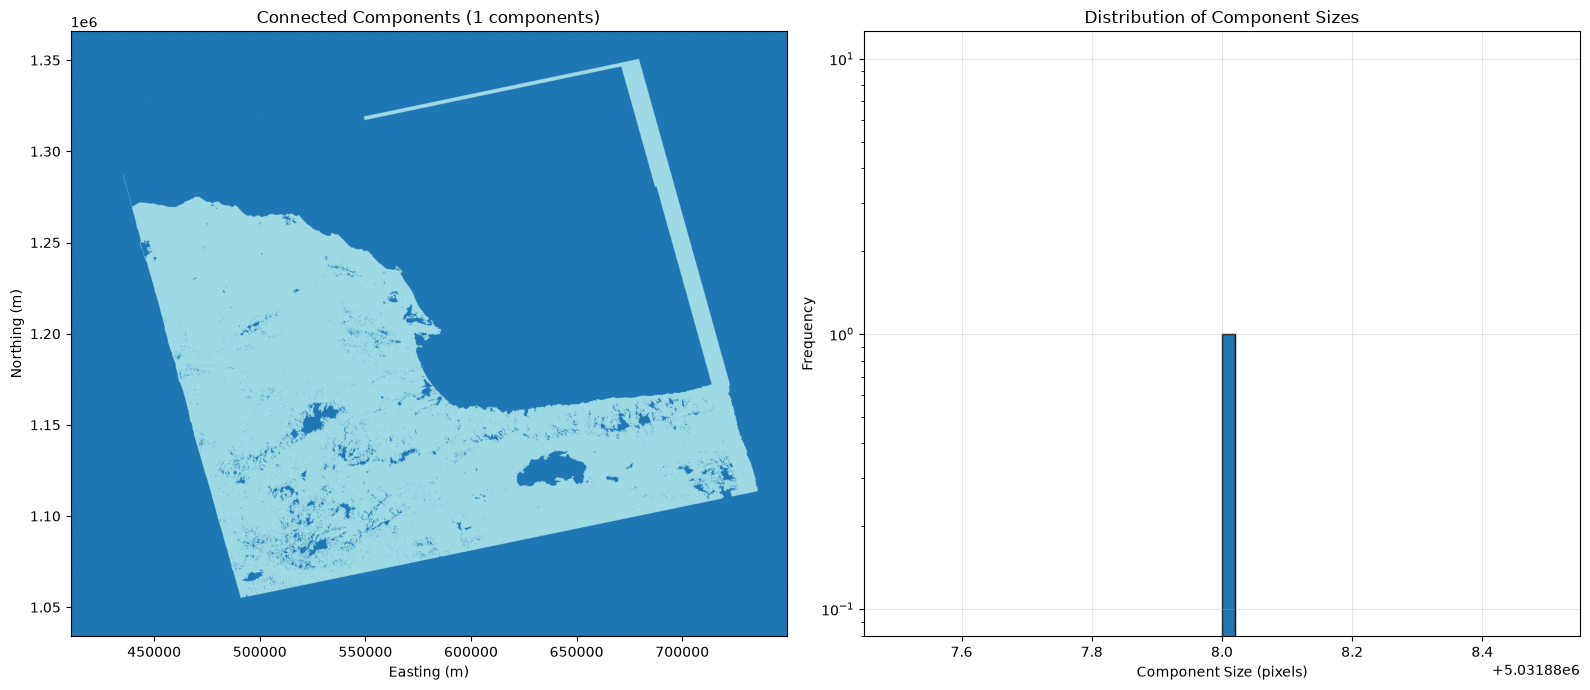


Connected Components Statistics:
  Total components: 1
  Largest component ID: 1
  Largest component size: 5031888 pixels (28.6%)
  Mean component size: 5031888.0 pixels
  Median component size: 5031888.0 pixels
  Components > 1000 pixels: 1


In [15]:
def read_connected_components(filename, polarization='HH'):
    """
    Read and analyze connected components
    """
    with h5py.File(filename, 'r') as f:
        base_path = f'/science/LSAR/GUNW/grids/frequencyA/unwrappedInterferogram/{polarization}'
        
        cc = f[f'{base_path}/connectedComponents'][:]
        x_coords = f[f'{base_path}/xCoordinates'][:]
        y_coords = f[f'{base_path}/yCoordinates'][:]
    
    # Analyze components
    unique_components = np.unique(cc[cc > 0])  # Exclude 0 (invalid)
    n_components = len(unique_components)
    
    # Calculate component sizes
    component_sizes = []
    for comp_id in unique_components:
        size = np.sum(cc == comp_id)
        component_sizes.append(size)
    
    component_sizes = np.array(component_sizes)
    largest_comp = unique_components[np.argmax(component_sizes)]
    
    # Plot
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    
    # Connected components map
    im1 = axes[0].imshow(cc, cmap='tab20', aspect='auto',
                         extent=[x_coords[0], x_coords[-1], y_coords[-1], y_coords[0]])
    axes[0].set_xlabel('Easting (m)')
    axes[0].set_ylabel('Northing (m)')
    axes[0].set_title(f'Connected Components ({n_components} components)')
    
    # Histogram of component sizes
    axes[1].hist(component_sizes, bins=50, edgecolor='black')
    axes[1].set_xlabel('Component Size (pixels)')
    axes[1].set_ylabel('Frequency')
    axes[1].set_title('Distribution of Component Sizes')
    axes[1].set_yscale('log')
    axes[1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    # Print statistics
    print(f"\nConnected Components Statistics:")
    print(f"  Total components: {n_components}")
    print(f"  Largest component ID: {largest_comp}")
    print(f"  Largest component size: {component_sizes.max()} pixels ({100*component_sizes.max()/cc.size:.1f}%)")
    print(f"  Mean component size: {component_sizes.mean():.1f} pixels")
    print(f"  Median component size: {np.median(component_sizes):.1f} pixels")
    print(f"  Components > 1000 pixels: {np.sum(component_sizes > 1000)}")
    
    return cc, component_sizes

# Example usage:
cc, sizes = read_connected_components(gunw_file, polarization='HH')

## 8. Mask Layer

**Path:** `/science/LSAR/GUNW/grids/frequencyA/unwrappedInterferogram/mask`

- **Data Type:** uint8
- **Grid Spacing:** 80 m
- **Description:** Pixel classification mask

### Mask Values:

The mask is a bit-encoded field with the following values:


In [16]:
def parse_mask(mask_value):
    """
    Decodes a 32-bit GUNW subswath and data anomaly mask.
    """
    
    # Bits 0–7: Subswath and Water encoding
    subswath_byte = mask_value & 0xFF
    
    # Extract digits from the 0-255 byte
    is_water = (subswath_byte // 100) == 1
    ref_subswath = (subswath_byte // 10) % 10
    sec_subswath = subswath_byte % 10
    
    # Bits 8–15: Secondary RSLC anomaly flags
    sec_anomaly = (mask_value >> 8) & 0xFF

    # Bits 16–23: Reference RSLC anomaly flags
    ref_anomaly = (mask_value >> 16) & 0xFF

    iono_mask = (mask_value >> 24) & 1
    
    # Bits 24–31: Reserved for future use
    reserved = (mask_value >> 25) & 0xFF

    binary_mask_ref = (ref_subswath > 0).astype(int)    
    binary_mask_sec = (sec_subswath > 0).astype(int)  
    
    return {
        "is_water": is_water,
        "ref_subswath": binary_mask_ref,
        "sec_subswath": binary_mask_sec,
        "sec_anomaly_raw": sec_anomaly,
        "ref_anomaly_raw": ref_anomaly,
        "is_valid_subswath": (ref_subswath > 0) & (sec_subswath > 0),
        "no_anomalies": (ref_anomaly == 0) & (sec_anomaly == 0),
        "iono_mask": iono_mask
    }


with h5py.File(gunw_file, 'r') as f:
    mask_path = '/science/LSAR/GUNW/grids/frequencyA/unwrappedInterferogram/mask'
    mask_values = f[mask_path][:]
    mask_dict = parse_mask(mask_values)

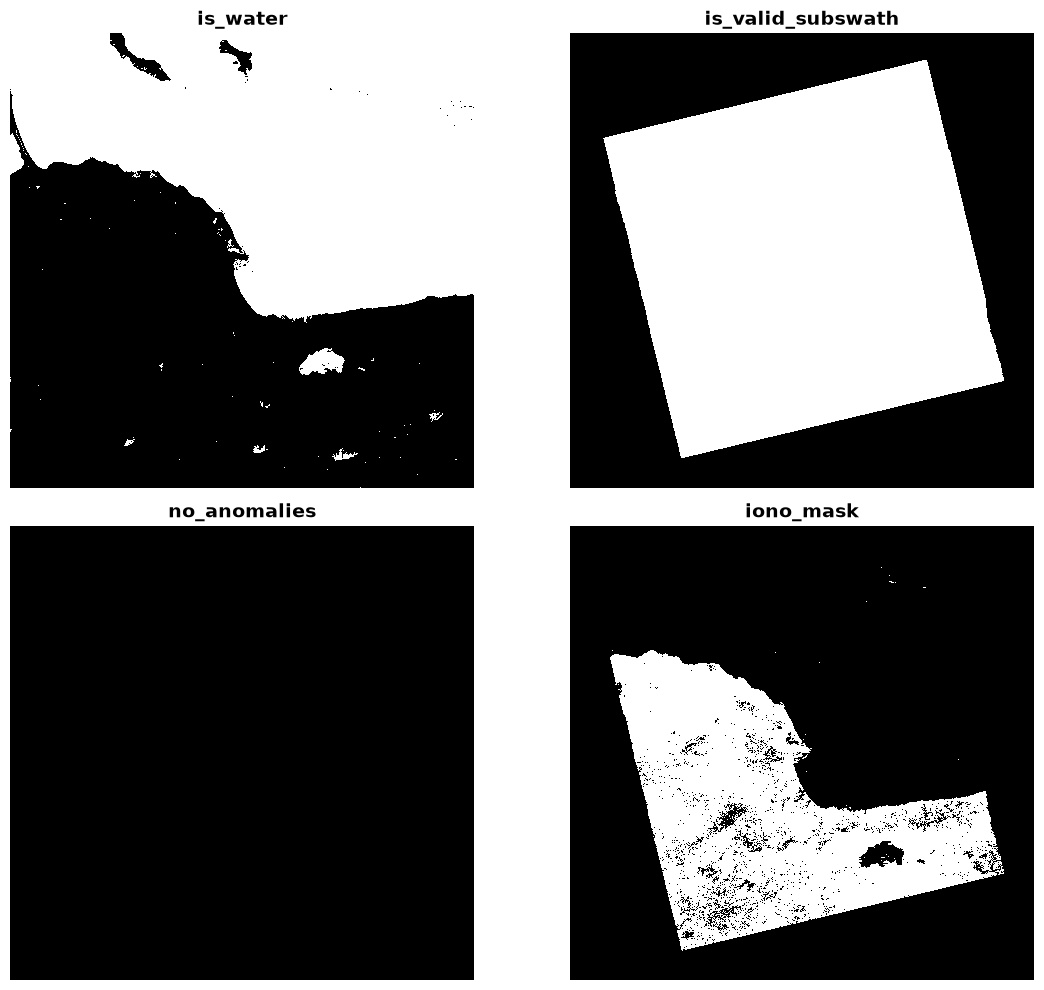

In [17]:
keys_to_plot = ["is_water", "is_valid_subswath", "no_anomalies", "iono_mask"]

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(12, 10))
axes = axes.flatten()  # Flatten into a 1D array for easier indexing

for i, key in enumerate(keys_to_plot):
    if key in mask_dict:
        # cmap='gray' displays False/0 as black and True/1 as white
        im = axes[i].imshow(mask_dict[key], cmap='gray', interpolation='nearest')
        axes[i].set_title(key, fontsize=14, fontweight='bold')
        axes[i].axis('off')  # Hide axis ticks for a cleaner spatial layout
    else:
        axes[i].text(0.5, 0.5, f"Key '{key}'\nnot found", 
                     ha='center', va='center', color='red', fontsize=12)
        axes[i].axis('off')

plt.tight_layout()
plt.show()


In [18]:
combined_valid_mask = (
    ~mask_dict["is_water"] & 
    mask_dict["is_valid_subswath"] & 
    mask_dict["no_anomalies"]
)

phase_masked = np.where(combined_valid_mask, phase, np.nan)



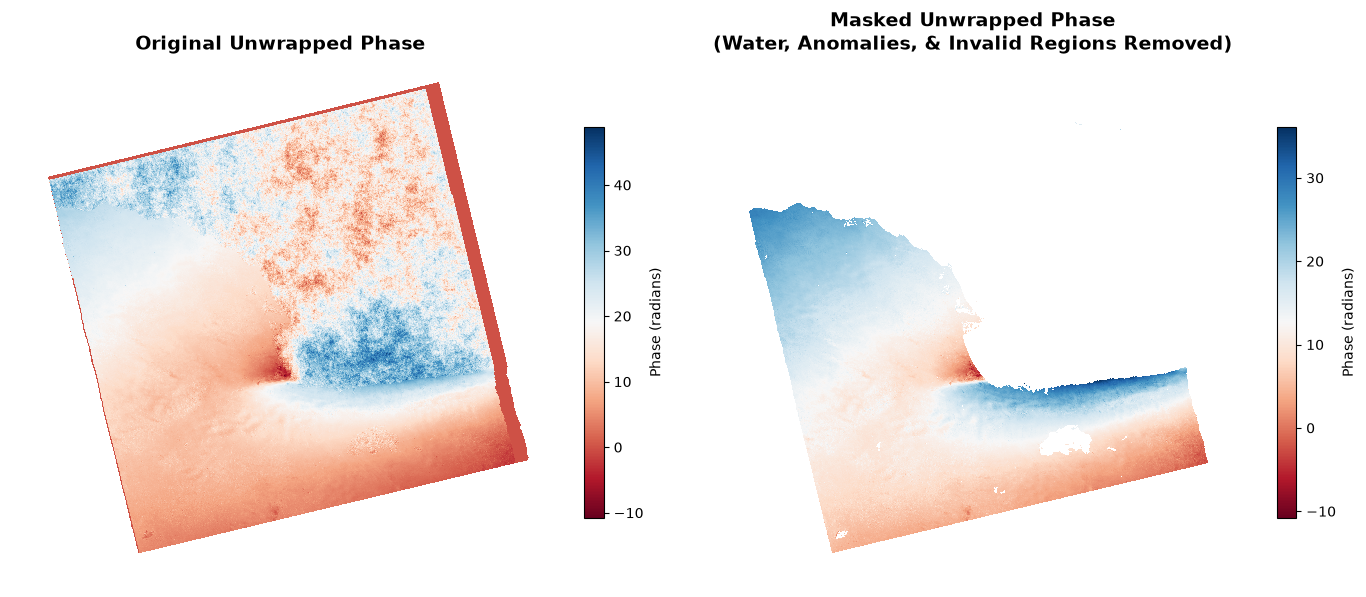

In [19]:

# Set up a 1x2 plotting grid
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 6))

# 1. Plot the original unmasked phase
im1 = axes[0].imshow(phase, cmap='RdBu', interpolation='nearest')
axes[0].set_title("Original Unwrapped Phase", fontsize=14, fontweight='bold')
axes[0].axis('off')
fig.colorbar(im1, ax=axes[0], label='Phase (radians)', shrink=0.7)

# 2. Plot the masked phase (NaN values will automatically show as transparent/blank)
im2 = axes[1].imshow(phase_masked, cmap='RdBu', interpolation='nearest')
axes[1].set_title("Masked Unwrapped Phase\n(Water, Anomalies, & Invalid Regions Removed)", 
                  fontsize=14, fontweight='bold')
axes[1].axis('off')
fig.colorbar(im2, ax=axes[1], label='Phase (radians)', shrink=0.7)

# Optimize spacing and display
plt.tight_layout()
plt.show()


In [20]:
phase_iono_corrected = phase - iono
iono_masked = np.where(combined_valid_mask, iono, np.nan)
phase_iono_corrected_masekd = np.where(combined_valid_mask, phase_iono_corrected, np.nan)

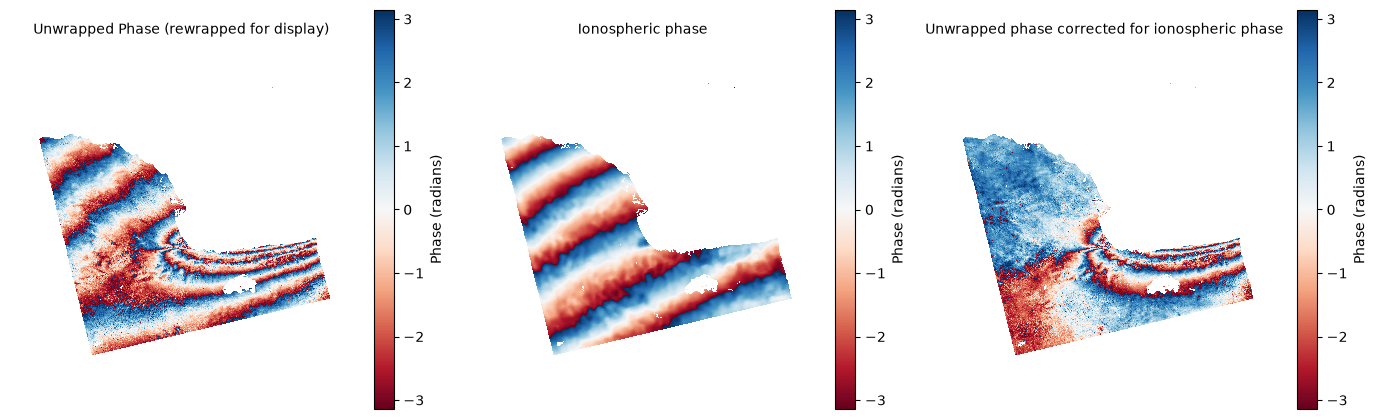

In [21]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(14, 6))

# 1. Plot the original unmasked phase
im1 = axes[0].imshow(np.angle(np.exp(1J*phase_masked)), cmap='RdBu', interpolation='nearest')
axes[0].set_title("Unwrapped Phase (rewrapped for display)", fontsize=10)
axes[0].axis('off')
fig.colorbar(im1, ax=axes[0], label='Phase (radians)', shrink=0.7)

# 2. Plot the masked phase (NaN values will automatically show as transparent/blank)
im2 = axes[1].imshow(np.angle(np.exp(1J*iono_masked)), cmap='RdBu', interpolation='nearest')
axes[1].set_title("Ionospheric phase", 
                  fontsize=10)
axes[1].axis('off')
fig.colorbar(im2, ax=axes[1], label='Phase (radians)', shrink=0.7)

im3 = axes[2].imshow(np.angle(np.exp(1J*phase_iono_corrected_masekd)), cmap='RdBu', interpolation='nearest')
axes[2].set_title("Unwrapped phase corrected for ionospheric phase", 
                  fontsize=10 )
axes[2].axis('off')
fig.colorbar(im3, ax=axes[2], label='Phase (radians)', shrink=0.7)


# Optimize spacing and display
plt.tight_layout()
plt.show()


## 9. Pixel Offsets

Pixel offsets are measurements of ground displacement in two directions, derived from incoherent cross-correlation.

### 9.1 Along-Track Offset

**Path:** `/science/LSAR/GUNW/grids/frequencyA/pixelOffsets/[HH/VV]/alongTrackOffset`

- **Units:** Meters
- **Data Type:** float32
- **Grid Spacing:** 80 m
- **Description:** Displacement in satellite flight direction

### 9.2 Slant Range Offset

**Path:** `/science/LSAR/GUNW/grids/frequencyA/pixelOffsets/[HH/VV]/slantRangeOffset`

- **Units:** Meters
- **Data Type:** float32
- **Grid Spacing:** 80 m
- **Description:** Displacement in radar line-of-sight direction

### 9.3 Correlation Surface Peak

**Path:** `/science/LSAR/GUNW/grids/frequencyA/pixelOffsets/[HH/VV]/correlationSurfacePeak`

- **Units:** Dimensionless (0-1)
- **Description:** Quality metric for offset measurements

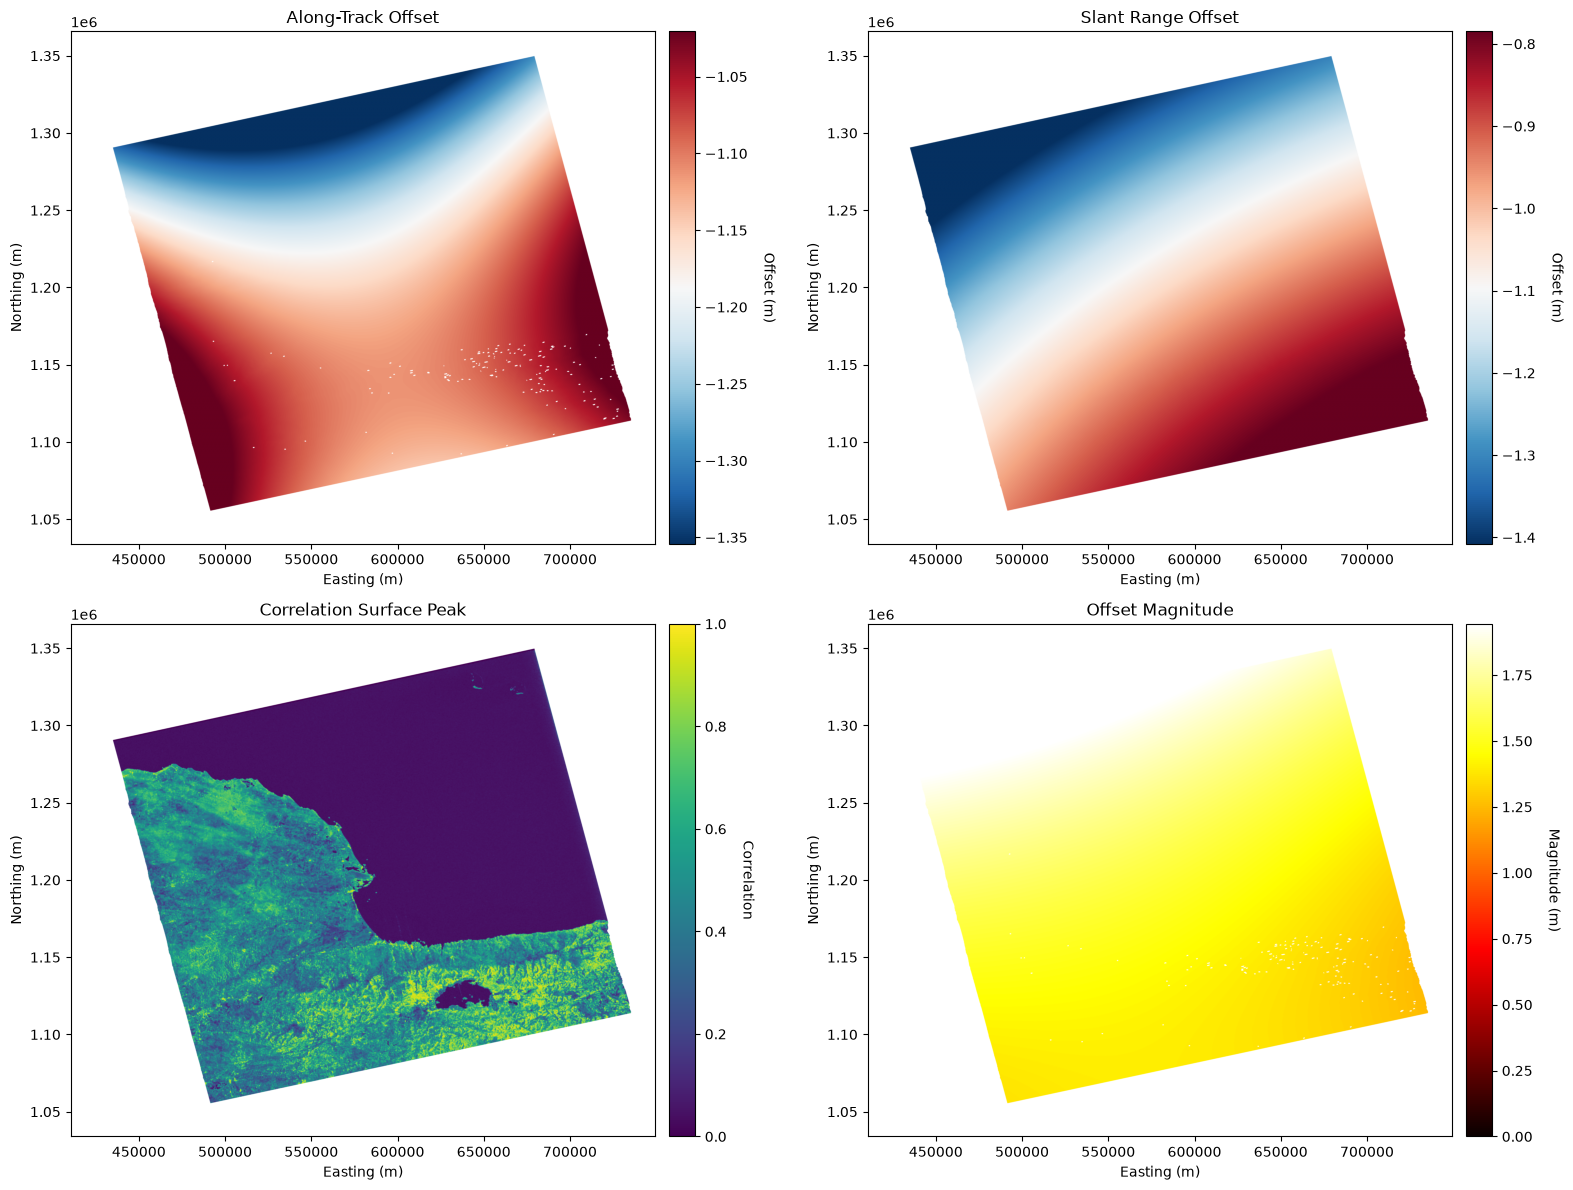


Pixel Offset Statistics:
  Along-Track Offset:
    Mean: -1.153 m
    Std: 0.100 m
  Slant Range Offset:
    Mean: -1.072 m
    Std: 0.195 m
  Correlation Peak:
    Mean: 0.289
    High quality (>0.5): 13.6%


In [22]:
def read_pixel_offsets(filename, polarization='HH'):
    """
    Read and display pixel offsets
    """
    with h5py.File(filename, 'r') as f:
        base_path = f'/science/LSAR/GUNW/grids/frequencyA/pixelOffsets/{polarization}'
        
        along_track = f[f'{base_path}/alongTrackOffset'][:]
        slant_range = f[f'{base_path}/slantRangeOffset'][:]
        corr_peak = f[f'{base_path}/correlationSurfacePeak'][:]
        
        x_coords = f[f'{base_path}/xCoordinates'][:]
        y_coords = f[f'{base_path}/yCoordinates'][:]
    
    # Plot
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    
    extent = [x_coords[0], x_coords[-1], y_coords[-1], y_coords[0]]
    
    # Along-track offset
    im1 = axes[0,0].imshow(along_track, cmap='RdBu_r', aspect='auto', extent=extent,
                          vmin=np.nanpercentile(along_track, 5),
                          vmax=np.nanpercentile(along_track, 95))
    axes[0,0].set_title('Along-Track Offset')
    axes[0,0].set_xlabel('Easting (m)')
    axes[0,0].set_ylabel('Northing (m)')
    cbar1 = plt.colorbar(im1, ax=axes[0,0], orientation='vertical', pad=0.02)
    cbar1.set_label('Offset (m)', rotation=270, labelpad=20)
    
    # Slant range offset
    im2 = axes[0,1].imshow(slant_range, cmap='RdBu_r', aspect='auto', extent=extent,
                          vmin=np.nanpercentile(slant_range, 5),
                          vmax=np.nanpercentile(slant_range, 95))
    axes[0,1].set_title('Slant Range Offset')
    axes[0,1].set_xlabel('Easting (m)')
    axes[0,1].set_ylabel('Northing (m)')
    cbar2 = plt.colorbar(im2, ax=axes[0,1], orientation='vertical', pad=0.02)
    cbar2.set_label('Offset (m)', rotation=270, labelpad=20)
    
    # Correlation peak
    im3 = axes[1,0].imshow(corr_peak, cmap='viridis', vmin=0, vmax=1, aspect='auto', extent=extent)
    axes[1,0].set_title('Correlation Surface Peak')
    axes[1,0].set_xlabel('Easting (m)')
    axes[1,0].set_ylabel('Northing (m)')
    cbar3 = plt.colorbar(im3, ax=axes[1,0], orientation='vertical', pad=0.02)
    cbar3.set_label('Correlation', rotation=270, labelpad=20)
    
    # Offset magnitude
    offset_mag = np.sqrt(along_track**2 + slant_range**2)
    im4 = axes[1,1].imshow(offset_mag, cmap='hot', aspect='auto', extent=extent,
                          vmin=0, vmax=np.nanpercentile(offset_mag, 95))
    axes[1,1].set_title('Offset Magnitude')
    axes[1,1].set_xlabel('Easting (m)')
    axes[1,1].set_ylabel('Northing (m)')
    cbar4 = plt.colorbar(im4, ax=axes[1,1], orientation='vertical', pad=0.02)
    cbar4.set_label('Magnitude (m)', rotation=270, labelpad=20)
    
    plt.tight_layout()
    plt.show()
    
    print(f"\nPixel Offset Statistics:")
    print(f"  Along-Track Offset:")
    print(f"    Mean: {np.nanmean(along_track):.3f} m")
    print(f"    Std: {np.nanstd(along_track):.3f} m")
    print(f"  Slant Range Offset:")
    print(f"    Mean: {np.nanmean(slant_range):.3f} m")
    print(f"    Std: {np.nanstd(slant_range):.3f} m")
    print(f"  Correlation Peak:")
    print(f"    Mean: {np.nanmean(corr_peak):.3f}")
    print(f"    High quality (>0.5): {100*np.sum(corr_peak>0.5)/corr_peak.size:.1f}%")
    
    return along_track, slant_range, corr_peak

# Example usage:
az_off, rg_off, corr = read_pixel_offsets(gunw_file, polarization='HH')

## 10. Metadata Cube

**Path:** `/science/LSAR/GUNW/metadata/radarGrid/`

Metadata cubes are 3D arrays that provide radar geometry information organized over a geographic grid with height dependence.

### Key Metadata Cubes:

1. **incidenceAngle**: Local incidence angle (degrees)
2. **slantRange**: Slant range distance (m)
3. **zeroDopplerAzimuthTime**: Azimuth time (seconds)
4. **parallelBaseline**: Parallel baseline component (m)
5. **perpendicularBaseline**: Perpendicular baseline component (m)
6. **losUnitVectorX/Y**: Line-of-sight unit vector components
7. **alongTrackUnitVectorX/Y**: Along-track unit vector components
8. **elevationAngle**: Elevation angle (degrees)
9. **groundTrackVelocity**: Ground track velocity (m/s)

### Dimensions:
- **X**: Geographic easting
- **Y**: Geographic northing
- **Z**: Height above ellipsoid

### Usage:
Metadata cubes allow height-dependent interpolation of radar geometry parameters for any point in the scene.
A digital elevation model that covers the NISAR product is required to interpolate the metadata cube. We should make sure the provided DEM is exactly on the same grid (projection system) of the GUNW product.

Let's first extract the geolocation information of the GUNW product. We will next use these information to reproject the DEM to the grid of the GUNW product.

In [25]:
def read_gunw_grid_info(gunw_file, polarization='HH'):
    """
    Read grid information from GUNW product
    
    Parameters:
    -----------
    gunw_file : str
        Path to GUNW HDF5 file
    polarization : str
        Polarization (HH or VV)
    
    Returns:
    --------
    grid_info : dict
        Dictionary containing:
        - x_coords: X coordinates (easting)
        - y_coords: Y coordinates (northing)
        - epsg: EPSG code
        - projection_wkt: Projection in WKT format
        - bbox: Bounding box (xmin, ymin, xmax, ymax)
        - shape: Grid shape (ny, nx)
    """
    with h5py.File(gunw_file, 'r') as f:
        base_path = f'/science/LSAR/GUNW/grids/frequencyA/unwrappedInterferogram/{polarization}'
        
        # Read coordinates
        x_coords = f[f'{base_path}/xCoordinates'][:]
        y_coords = f[f'{base_path}/yCoordinates'][:]
        
        # Read projection
        projection = f[f'{base_path}/projection'][()]
        #if isinstance(projection, bytes):
        #    projection = projection.decode('utf-8')
        
        # Read sample data to get shape
        sample_data = f[f'{base_path}/unwrappedPhase']
        shape = sample_data.shape
    
    # Extract EPSG code from projection
    #srs = osr.SpatialReference()
    #srs.ImportFromWkt(projection)
    #epsg = None
    #if srs.GetAuthorityName(None) == 'EPSG':
    #    epsg = int(srs.GetAuthorityCode(None))
    epsg = int(projection)
    # Calculate bounding box
    bbox = {
        'xmin': x_coords.min(),
        'xmax': x_coords.max(),
        'ymin': y_coords.min(),
        'ymax': y_coords.max()
    }
    
    grid_info = {
        'x_coords': x_coords,
        'y_coords': y_coords,
        'epsg': epsg,
        'projection_wkt': projection,
        'bbox': bbox,
        'shape': shape,
        'x_spacing': np.median(np.diff(x_coords)),
        'y_spacing': np.median(np.diff(y_coords))
    }
    
    print("GUNW Grid Information:")
    print(f"  EPSG Code: {epsg}")
    print(f"  Grid Shape: {shape}")
    print(f"  X Range: {bbox['xmin']:.2f} to {bbox['xmax']:.2f}")
    print(f"  Y Range: {bbox['ymin']:.2f} to {bbox['ymax']:.2f}")
    print(f"  X Spacing: {grid_info['x_spacing']:.2f} m")
    print(f"  Y Spacing: {grid_info['y_spacing']:.2f} m")
    
    return grid_info

# Example usage:

grid_info = read_gunw_grid_info(gunw_file, polarization='HH')
grid_info

GUNW Grid Information:
  EPSG Code: 32619
  Grid Shape: (4149, 4239)
  X Range: 410440.00 to 749480.00
  Y Range: 1033960.00 to 1365800.00
  X Spacing: 80.00 m
  Y Spacing: -80.00 m


{'x_coords': array([410440., 410520., 410600., ..., 749320., 749400., 749480.]),
 'y_coords': array([1365800., 1365720., 1365640., ..., 1034120., 1034040., 1033960.]),
 'epsg': 32619,
 'projection_wkt': 32619,
 'bbox': {'xmin': 410440.0,
  'xmax': 749480.0,
  'ymin': 1033960.0,
  'ymax': 1365800.0},
 'shape': (4149, 4239),
 'x_spacing': 80.0,
 'y_spacing': -80.0}

In [26]:
from osgeo import gdal, osr

def get_gunw_bbox_latlon(hdf5_file_path: str) -> dict:
    """
    Extracts the WGS 84 (Lat/Lon) bounding box from a NISAR L2 GUNW product.
    Automatically handles any native projection (e.g., UTM grids).
    
    Parameters:
        hdf5_file_path (str): Path to the NISAR L2 GUNW HDF5 file.
        
    Returns:
        dict: A dictionary containing min/max latitude and longitude values.
    """
    # Subdataset path template matching standard NISAR L2 layout
    subdataset_path = f"NETCDF:{hdf5_file_path}://science/LSAR/GUNW/grids/frequencyA/unwrappedInterferogram/HH/unwrappedPhase"
    
    # Open the dataset via GDAL
    ds = gdal.Open(subdataset_path)
    if ds is None:
        raise FileNotFoundError(f"Could not open standard NISAR subdataset at: {subdataset_path}")
        
    # Extract dimensions and transformation matrix
    width = ds.RasterXSize
    height = ds.RasterYSize
    gt = ds.GetGeoTransform()  
    
    # Compute the 4 native corners (Upper Left, Lower Left, Lower Right, Upper Right)
    native_corners = [
        (gt[0], gt[3]),                                      # UL
        (gt[0] + height * gt[2], gt[3] + height * gt[5]),    # LL
        (gt[0] + width * gt[1] + height * gt[2], gt[3] + width * gt[4] + height * gt[5]), # LR
        (gt[0] + width * gt[1], gt[3] + width * gt[4])       # UR
    ]
    
    # Initialize Spatial Reference Objects
    src_srs = osr.SpatialReference(wkt=ds.GetProjection())
    tgt_srs = osr.SpatialReference()
    tgt_srs.ImportFromEPSG(4326)  # WGS 84 target standard
    
    # Enforce GIS order (X=Longitude, Y=Latitude)
    src_srs.SetAxisMappingStrategy(osr.OAMS_TRADITIONAL_GIS_ORDER)
    tgt_srs.SetAxisMappingStrategy(osr.OAMS_TRADITIONAL_GIS_ORDER)
    
    transform = osr.CoordinateTransformation(src_srs, tgt_srs)
    
    # Transform native coordinates to Geographic Lat/Lon
    lons = []
    lats = []
    for x, y in native_corners:
        lon, lat, _ = transform.TransformPoint(x, y)
        lons.append(lon)
        lats.append(lat)
        
    # Explicit resource cleanup for GDAL pointer
    ds = None
    
    # Return bounding box dictionary
    return {
        "lon_min": min(lons),
        "lat_min": min(lats),
        "lon_max": max(lons),
        "lat_max": max(lats)
    }

# --- Example Usage ---
# file_path = "NISAR_L2_PR_GUNW_...h5"
bbox = get_gunw_bbox_latlon(gunw_file)
print(bbox)


{'lon_min': -69.82414755943846, 'lat_min': 9.34609960743513, 'lon_max': -66.7054583854008, 'lat_max': 12.354030384982725}


Now let's use available public tools and data to download copernicus DEM that coveres our GUNW product

In [27]:
import rasterio
from dem_stitcher.stitcher import stitch_dem

# Format into the standard list layout: [xmin, ymin, xmax, ymax]
bounds = [bbox["lon_min"], bbox["lat_min"], bbox["lon_max"], bbox["lat_max"]]

#Download and stitch the DEM over your exact bounding box
# 'glo_30' retrieves the 30-meter Copernicus Global DEM
print("Downloading and stitching DEM tiles...")
dem_array, dem_profile = stitch_dem(
    bounds,
    dem_name='glo_30',
    dst_ellipsoidal_height=True,  # Set to True if you need ellipsoidal heights instead of geoid
    dst_area_or_point='Point'
)

# 3. Export the stitched array directly to a local GeoTIFF file
output_dem_path = "nisar_gunw_dem.tif"
with rasterio.open(output_dem_path, 'w', **dem_profile) as dst:
    dst.write(dem_array, 1)

print(f"DEM successfully downloaded and saved to: {output_dem_path}")
print(f"DEM Shape: {dem_array.shape}")


Reading tile imagery: 100%|████████████████████| 15/15 [00:19<00:00,  1.32s/it]


DEM successfully downloaded and saved to: nisar_gunw_dem.tif
DEM Shape: (10830, 11228)


The following function ensures that the provided DEM is on the exact grid of the GUNW product. 

In [28]:
def reproject_dem_to_bbox(input_dem_path, output_dem_path, target_epsg, bbox, target_width, target_height):
    """
    Reprojects a DEM using exact target pixel dimensions to guarantee matching grid shapes.
    """
    src_ds = gdal.Open(input_dem_path)
    if src_ds is None:
        raise FileNotFoundError(f"Could not open input DEM at {input_dem_path}")
        

    # Define warp options using width and height instead of xRes and yRes
    warp_options = gdal.WarpOptions(
        dstSRS=f'EPSG:{target_epsg}',
        outputBounds=bbox,              # [minx, miny, maxx, maxy]
        width=target_width,             # Exact pixel width of target GUNW layer
        height=target_height,           # Exact pixel height of target GUNW layer
        resampleAlg=gdal.GRIORA_Bilinear,
        dstNodata=-9999                 
    )

    gdal.Warp(output_dem_path, src_ds, options=warp_options)
    src_ds = None
    print(f"Successfully reprojected DEM saved to: {output_dem_path}")


input_dem = "nisar_gunw_dem.tif"
gunw_dem = "NISAR_GUNW_DEM.tif"
output_bbox = [grid_info['bbox']['xmin'], grid_info['bbox']['ymin'], grid_info['bbox']['xmax'], grid_info['bbox']['ymax']]
target_res = grid_info['x_spacing']

reproject_dem_to_bbox(
    input_dem, 
    gunw_dem, 
    grid_info['epsg'], 
    output_bbox, 
    grid_info['shape'][1],   # Add your target raster width variable
    grid_info['shape'][0]   # Add your target raster height variable
)


Successfully reprojected DEM saved to: NISAR_GUNW_DEM.tif


Now the following function interpolates any GUNW three dimensional metadata cube to a two dimensional dataset.

In [29]:
import numpy as np
import h5py
from osgeo import gdal
from scipy.interpolate import RegularGridInterpolator

def interpolate_nisar_cube_to_dem(gunw_path, cube_dataset, dem_path, output_path):
    """
    Interpolates a 3D NISAR L2 metadata cube layer to a 2D grid matching a DEM's
    exact coordinates and local topography heights.
    
    Parameters:
    - gunw_path (str): Path to the NISAR L2 GUNW HDF5 file.
    - cube_dataset (str): Name of the 3D dataset to be evaluated on the DEM grid
    - dem_path (str): Path to the target reprojected DEM (GeoTIFF format).
    - output_path (str): Path to save the interpolated 2D output layer.
    """
    radar_cube_path = "/science/LSAR/GUNW/metadata/radarGrid" 
    # 1. Read the DEM data and its geographic grid
    dem_ds = gdal.Open(dem_path)
    if dem_ds is None:
        raise FileNotFoundError(f"Could not open DEM at {dem_path}")
        
    geotransform = dem_ds.GetGeoTransform()
    dem_width = dem_ds.RasterXSize
    dem_height = dem_ds.RasterYSize
    dem_data = dem_ds.ReadAsArray() # Matrix of heights (Z)
    
    # Generate 1D coordinate vectors matching the pixel centers of the DEM
    dem_x = geotransform[0] + (np.arange(dem_width) + 0.5) * geotransform[1]
    dem_y = geotransform[3] + (np.arange(dem_height) + 0.5) * geotransform[5]

    cube_group_path = f"{radar_cube_path}/{cube_dataset}"
    cube_x_path = f"{radar_cube_path}/xCoordinates"
    cube_y_path = f"{radar_cube_path}/yCoordinates"
    cube_z_path = f"{radar_cube_path}/heightAboveEllipsoid"
    # 2. Extract the NISAR 3D metadata cube and its axis coordinate definitions
    with h5py.File(gunw_path, 'r') as h5:
        cube_ds = h5[cube_group_path]
        cube_data = cube_ds[:]  # Shape typically expected: (len(cube_z), len(cube_y), len(cube_x))
        
        # Read the coordinate axes vectors from HDF5 attributes or parallel coordinate datasets
        cube_x = h5[cube_x_path][:]
        cube_y = h5[cube_y_path][:]
        cube_z = h5[cube_z_path][:]
        
    # 3. Create the 3D Regular Grid Interpolator
    # Ensure dimensions match your cube structure. If data is (Z, Y, X), order the axes accordingly
    interpolator = RegularGridInterpolator(
        (cube_z, cube_y, cube_x), 
        cube_data, 
        method='linear', 
        bounds_error=False, 
        fill_value=np.nan
    )
    
    # 4. Construct the high-resolution interpolation grid query
    # Meshgrid creates 2D arrays matching the DEM footprint
    dem_X, dem_Y = np.meshgrid(dem_x, dem_y)
    
    # Flatten everything to pass as a N x 3 column matrix: [Z_dem, Y_dem, X_dem]
    query_points = np.column_stack((
        dem_data.ravel(),  # The local height profile dictates the Z slice queried
        dem_Y.ravel(), 
        dem_X.ravel()
    ))
    
    # 5. Execute 3D Interpolation
    print("Interpolating 3D cube onto DEM target grid...")
    interpolated_flat = interpolator(query_points)
    
    # Reshape back to the original 2D DEM shape
    interpolated_2d = interpolated_flat.reshape((dem_height, dem_width))
    
    # 6. Save the output to a GeoTIFF maintaining spatial metadata
    driver = gdal.GetDriverByName("GTiff")
    out_ds = driver.Create(output_path, dem_width, dem_height, 1, gdal.GDT_Float32)
    out_ds.SetGeoTransform(geotransform)
    out_ds.SetProjection(dem_ds.GetProjection())
    
    out_band = out_ds.GetRasterBand(1)
    out_band.WriteArray(interpolated_2d)
    out_band.SetNoDataValue(np.nan)
    
    # Flush buffers
    out_band.FlushCache()
    dem_ds = None
    out_ds = None
    print(f"Interpolated layer successfully saved to {output_path}")

    return interpolated_2d

## Tropospheric phase delay

In [30]:
tropo_phase_wet_file = "tropo_phase_wet.tif"
tropo_phase_hydro_file = "tropo_phase_hydro.tif"
tropo_phase_wet = interpolate_nisar_cube_to_dem(gunw_file, "wetTroposphericPhaseScreen", gunw_dem, tropo_phase_wet_file)
tropo_phase_hydro = interpolate_nisar_cube_to_dem(gunw_file, "hydrostaticTroposphericPhaseScreen", gunw_dem, tropo_phase_hydro_file)
tropo_phae = tropo_phase_wet + tropo_phase_hydro

Interpolating 3D cube onto DEM target grid...
Interpolated layer successfully saved to tropo_phase_wet.tif
Interpolating 3D cube onto DEM target grid...
Interpolated layer successfully saved to tropo_phase_hydro.tif


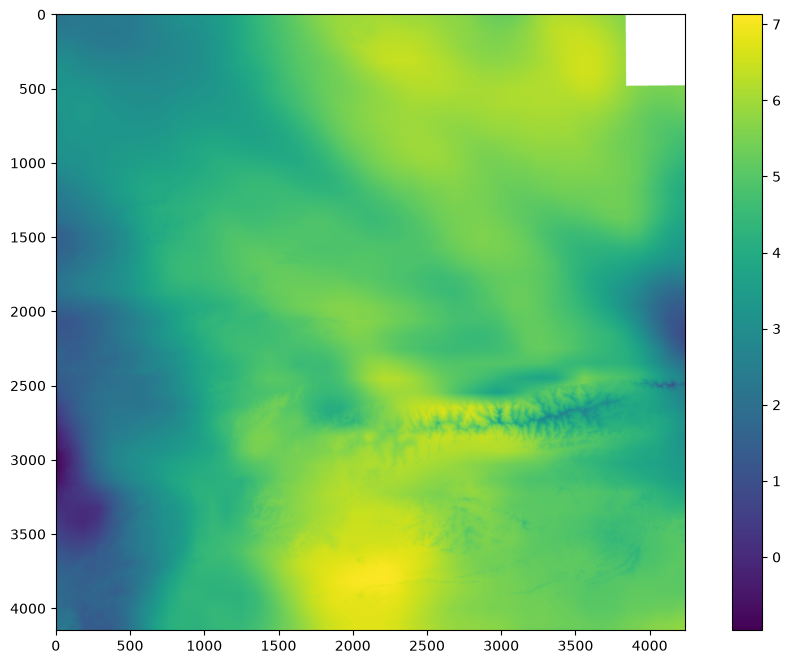

In [31]:
plt.imshow(tropo_phae)
plt.colorbar()

## Solid earth tide

In [32]:
solid_earth_tide_file = "solid_earth_tide.tif"
solid_earth_tide = interpolate_nisar_cube_to_dem(gunw_file, "slantRangeSolidEarthTidesPhase", gunw_dem, solid_earth_tide_file)

Interpolating 3D cube onto DEM target grid...
Interpolated layer successfully saved to solid_earth_tide.tif


# Interferogram corrected for ionosphere, troposphere and solid earth tide
Now that we have ionospheric phase, troposoheric phase and silud earth tide, we can remove all those components from our unwrapped phase as:


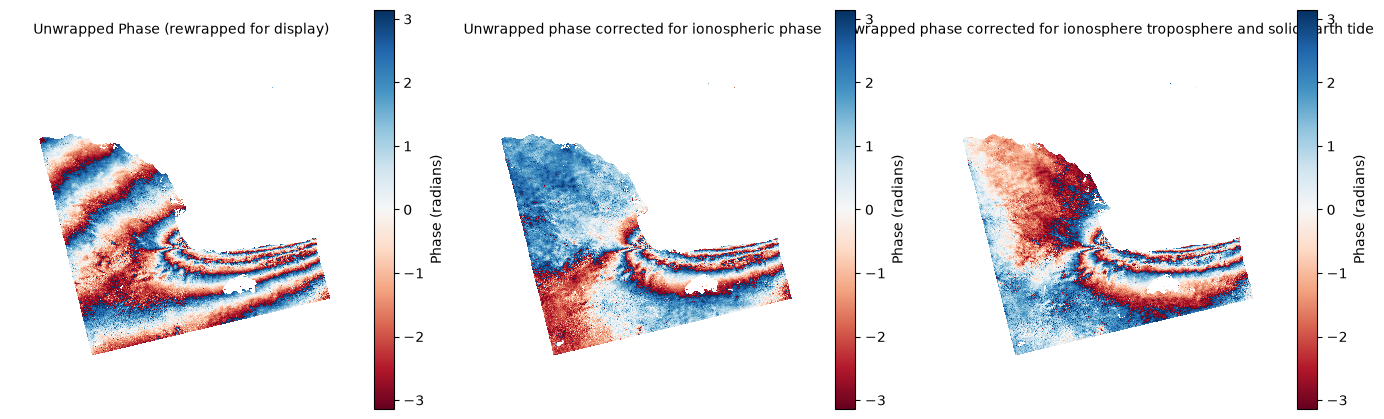

In [33]:
phase_corrected = phase - iono - tropo_phae - solid_earth_tide

phase_corrected_masked = np.where(combined_valid_mask, phase_corrected, np.nan)



fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(14, 6))

# 1. Plot the original unmasked phase
im1 = axes[0].imshow(np.angle(np.exp(1J*phase_masked)), cmap='RdBu', interpolation='nearest')
axes[0].set_title("Unwrapped Phase (rewrapped for display)", fontsize=10)
axes[0].axis('off')
fig.colorbar(im1, ax=axes[0], label='Phase (radians)', shrink=0.7)

# 2. Plot the masked phase (NaN values will automatically show as transparent/blank)
im2 = axes[1].imshow(np.angle(np.exp(1J*phase_iono_corrected_masekd)), cmap='RdBu', interpolation='nearest')
axes[1].set_title("Unwrapped phase corrected for ionospheric phase", 
                  fontsize=10)
axes[1].axis('off')
fig.colorbar(im2, ax=axes[1], label='Phase (radians)', shrink=0.7)

im3 = axes[2].imshow(np.angle(np.exp(1J*phase_corrected_masked)), cmap='RdBu', interpolation='nearest')
axes[2].set_title("Unwrapped phase corrected for ionosphere troposphere and solid earth tide", 
                  fontsize=10 )
axes[2].axis('off')
fig.colorbar(im3, ax=axes[2], label='Phase (radians)', shrink=0.7)


# Optimize spacing and display
plt.tight_layout()
plt.show()


## 11. Phase Sign Convention

### IMPORTANT: Understanding Phase Signs

NISAR GUNW products follow this **phase sign convention**:

- **POSITIVE PHASE (+)**: Range increase → Moving AWAY from sensor (subsidence, extension)
- **NEGATIVE PHASE (-)**: Range decrease → Moving TOWARD sensor (uplift, compression)

### Mathematical Definition:

$$\phi = \phi_{\text{secondary}} - \phi_{\text{reference}}$$

Where:
- $\phi$: Interferometric phase
- $\phi_{\text{reference}}$: Phase from earlier acquisition
- $\phi_{\text{secondary}}$: Phase from later acquisition

### Relationship to Displacement:

$$\Delta R = -\frac{\lambda}{4\pi} \phi$$

Where:
- $\Delta R$: Line-of-sight displacement (positive = toward sensor)
- $\lambda$: Radar wavelength (L-band: ~24 cm)
- $\phi$: Interferometric phase

### Examples:

1. **Subsidence (sinking)**:
   - Ground moves DOWN
   - Range to sensor INCREASES
   - Phase is POSITIVE

2. **Uplift (rising)**:
   - Ground moves UP
   - Range to sensor DECREASES
   - Phase is NEGATIVE



## 12. Processing Information

**Path:** `/science/LSAR/GUNW/metadata/processingInformation/`

This group contains comprehensive information about how the GUNW product was generated.

### 12.1 Input Files

**Path:** `/science/LSAR/GUNW/metadata/processingInformation/inputs/`

Contains:
- Reference RSLC filename
- Secondary RSLC filename
- DEM source and description
- Orbit files
- Configuration files

In [34]:
def print_processing_inputs(filename):
    """
    Print input files used for processing
    """
    with h5py.File(filename, 'r') as f:
        inputs = f['/science/LSAR/GUNW/metadata/processingInformation/inputs']
        
        print("\nProcessing Inputs:")
        print("=" * 80)
        
        # List all datasets in inputs group
        for key in inputs.keys():
            value = inputs[key][()]
            if isinstance(value, bytes):
                value = value.decode('utf-8')
            print(f"  {key}:")
            print(f"    {value}")

# Example usage:
print_processing_inputs(gunw_file)


Processing Inputs:
  configFiles:
    None
  demSource:
    Digital Elevation Model (DEM) for the NASA-ISRO NISAR mission, version 1.2, based on the Copernicus DEM 30-m (2023_1), referenced to the WGS84 ellipsoid. This digital elevation model (DEM) was prepared at the Jet Propulsion Laboratory, California Institute of Technology, under contract with the National Aeronautics and Space Administration, using the Copernicus DEM 30-m COP-DEM_GLO-30-DGED/2023_1 model, provided by the European Space Agency (ESA). The Copernicus DEM 30-m was produced using Copernicus WorldDEM-30  DLR e.V. 2010-2014 and  Airbus Defence and Space GmbH 2014-2018 provided under COPERNICUS by the European Union and ESA; all rights reserved. The organizations in charge of the NISAR mission or the Copernicus programme by law or by delegation do not incur any liability for any use of the Copernicus WorldDEM-30. Users, including those who redistribute, adapt, modify, or combine the data contained in this DEM, must com

### 12.3 Algorithm Information

**Path:** `/science/LSAR/GUNW/metadata/processingInformation/algorithms/`

Documents algorithms used for:
- **coregistration**: Image alignment methods
- **interferogramFormation**: Phase and coherence computation
- **unwrapping**: Phase unwrapping algorithm
- **ionosphereEstimation**: Ionosphere correction methods
- **geocoding**: Projection and interpolation methods

In [35]:
def print_algorithms(filename):
    """
    Print algorithms used in processing
    """
    with h5py.File(filename, 'r') as f:
        algorithms = f['/science/LSAR/GUNW/metadata/processingInformation/algorithms']
        
        print("\nProcessing Algorithms:")
        print("=" * 80)
        
        def print_group(group, indent=0):
            for key in group.keys():
                item = group[key]
                if isinstance(item, h5py.Group):
                    print("  " * indent + f"{key}:")
                    print_group(item, indent + 1)
                else:
                    value = item[()]
                    if isinstance(value, bytes):
                        value = value.decode('utf-8')
                    print("  " * indent + f"{key}: {value}")
        
        print_group(algorithms, indent=1)

# Example usage:
print_algorithms(gunw_file)


Processing Algorithms:
  coregistration:
    coregistrationMethod: Coarse geometry coregistration with DEM and orbit ephemeris with cross-correlation refinement
    crossCorrelation: frequency
    crossCorrelationFilling: fill_smoothed
    crossCorrelationFilterKernel: boxcar
    crossCorrelationOutliers: median_filter
    geometryCoregistration: Range doppler to geogrid then geogrid to range doppler
    resampling: sinc
  geocoding:
    complexGeocodingInterpolation: BILINEAR
    demInterpolation: biquintic
    floatingGeocodingInterpolation: BILINEAR
    integerGeocodingInterpolation: nearest
  interferogramFormation:
    flatteningMethod: With geometry offsets
    multilooking: Spatial moving average with decimation
    wrappedInterferogramFiltering: no_filter
  ionosphereEstimation:
    ionosphereAlgorithm: Range split-spectrum with sub-band interferograms from the main band and the difference of the main and side band of the input RSLCs
    ionosphereFilling: nearest
    ionosphe

### 12.4 Run Configuration

**Path:** `/science/LSAR/GUNW/metadata/processingInformation/parameters/runConfigurationContents`

Complete run configuration file (YAML format) used for processing, including all parameters and input files.

In [36]:
def extract_run_config(filename, output_file='runconfig.yaml'):
    """
    Extract and save run configuration
    """
    with h5py.File(filename, 'r') as f:
        config_path = '/science/LSAR/GUNW/metadata/processingInformation/parameters/runConfigurationContents'
        
        if config_path in f:
            config = f[config_path][()]
            if isinstance(config, bytes):
                config = config.decode('utf-8')
            
            # Save to file
            with open(output_file, 'w') as out:
                out.write(config)
            
            print(f"Run configuration saved to: {output_file}")
            print(f"\nFirst 50 lines:\n")
            print('\n'.join(config.split('\n')[:50]))
        else:
            print("Run configuration not found in product")

# Example usage:
extract_run_config(gunw_file)

Run configuration saved to: runconfig.yaml

First 50 lines:

{'pge_name_group': {'pge_name': 'INSAR_L_PGE'}, 'input_file_group': {'reference_rslc_file': '/data/work/jobs/2026/08/11/09/39/SCIFLO_INSAR__pcm_r05.02.2_pge_r05.02.3-network_pair_023_162_007_full_individual_L_40_DH_05_DH_0_state-config-20260810T203001.981489Z/NISAR_L1_PR_RSLC_022_162_A_007_4005_DHDH_A_20260613T100656_20260613T100731_P05023_N_F_J_001.h5', 'secondary_rslc_file': '/data/work/jobs/2026/08/11/09/39/SCIFLO_INSAR__pcm_r05.02.2_pge_r05.02.3-network_pair_023_162_007_full_individual_L_40_DH_05_DH_0_state-config-20260810T203001.981489Z/NISAR_L1_PR_RSLC_023_162_A_007_4005_DHDH_A_20260625T100655_20260625T100730_P05023_N_F_J_002.h5', 'qa_rifg_input_file': 'RIFG_product.h5', 'qa_runw_input_file': 'RUNW_product.h5', 'qa_gunw_input_file': 'output/product.h5', 'qa_roff_input_file': 'ROFF_product.h5', 'qa_goff_input_file': 'GOFF_product.h5'}, 'dynamic_ancillary_file_group': {'dem_file': '/data/work/jobs/2026/08/11/09/39/SCIFLO_

## 13. QA Report and Browse

Quality assurance products are typically distributed alongside GUNW products:

### 13.1 Browse Images

- **Format**: PNG
- **Content**: Quick-look images of key datasets
  - Unwrapped phase (rewrapped)
- **Purpose**: Rapid visual quality assessment

### 13.2 QA Report

- **Format**: PDF
- **Content**: Statistical summaries and quality metrics
  - Mean coherence
  - Percentage of valid pixels
  - Unwrapping quality metrics
  - Ionosphere and coherence plots